# Cluster-then-classify workflow on `SMX_concentration.csv`

**Read this first.** The paper's pipeline needs *PPCP × treatment-process removal data* (peak areas in/out over 4 sampling trips) and *Abraham/log Kow descriptors per compound*. Your CSV is different: ~870 **sulfamethoxazole (SMX) concentration measurements** across European sites, with environmental/catchment predictors. So the paper's C1/C2 clustering and its 7 chemical descriptors can't be reproduced on it.

What this notebook does instead is apply the **same framework** to your data:

| Paper stage | Here |
|---|---|
| Cluster labels derived from observed behaviour (C1/C2) | Concentration classes derived from `Y_conc` (L1: K-means, K=3; L2: tertiles) |
| 7 chemical descriptors as predictors | Environmental / catchment / climate variables |
| SVM, LR, RF classifiers | same |
| 5-fold CV | same, plus a **location-grouped** CV (sites repeat, so plain CV leaks) |
| K-means on descriptors + overlap | same (Hungarian-matched overlap, ARI) |
| Kruskal–Wallis, p<0.05 | same, plus Benjamini–Hochberg correction |
| RF feature importance | same |

The **last section** contains the paper's actual removal-efficiency / C1 / C2 code, ready to run once you have a treatment-train table.

In [1]:
# !pip install -q pandas numpy scikit-learn scipy matplotlib kmodes   # uncomment if needed
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import kruskal
from scipy.optimize import linear_sum_assignment
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_validate
from sklearn.metrics import adjusted_rand_score, confusion_matrix

CSV_PATH = "/kaggle/input/datasets/busygeek/smx-concentration/SMX_concentration.csv"   # <- change if the file lives elsewhere
SEED = 42
K = 3                                # number of clusters (paper's C2 uses 3)
MAX_MISSING = 0.50                   # drop predictors missing in more than 50% of rows
USE_COUNTRY = False                  # one-hot country (21 levels) if True

## 1. Load and inspect

In [2]:
df = pd.read_csv(CSV_PATH)
print(df.shape)
display(df.head())
print("\nWater matrix:\n", df.water_matrix.value_counts())
print("\nMissing fraction (top):\n", df.isna().mean().sort_values(ascending=False).head(12).round(2))
# Y_conc is log10(concentration + 1)
print("\nY_conc == log10(conc+1):", np.allclose(np.log10(df.concentration_ng_L + 1), df.Y_conc))

(871, 37)


,site_id,country,latitude,longitude,sampling_date,water_matrix,concentration_ng_L,month,year,day_of_year,...,dist_to_WWTP,dist_to_urban_area,pH,EC,TOC,COD,nutrients,turbidity,suspended_solids,Y_conc
0,771,Italy,45.551944,8.973056,2006-12-13,river/lake,131.0,12.0,2006.0,347.0,...,1.245786,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.120574
1,772,Italy,45.518889,9.041944,2006-12-13,river/lake,117.0,12.0,2006.0,347.0,...,4.349366,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.071882
2,773,Italy,45.296667,9.388889,2006-06-29,river/lake,60.0,6.0,2006.0,180.0,...,0.782883,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.785330
3,774,Italy,45.538056,9.182222,2006-10-04,river/lake,49.0,10.0,2006.0,277.0,...,1.940980,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.698970
4,775,Italy,45.889167,11.605000,2006-06-29,river/lake,13.0,6.0,2006.0,180.0,...,8.793537,0.141435,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.146128



Water matrix:
 water_matrix
river/lake      670
municipal_ww    184
groundwater      17
Name: count, dtype: int64

Missing fraction (top):
 COD                   1.00
turbidity             1.00
nutrients             0.97
TOC                   0.92
suspended_solids      0.91
pH                    0.86
EC                    0.85
rainfall_anomaly      0.10
rainfall_1d           0.09
air_temperature       0.09
rainfall_30d          0.09
evapotranspiration    0.09
dtype: float64

Y_conc == log10(conc+1): True


## 2. Preprocessing
Analogue of the paper's missing-data step: drop predictors that are mostly empty (pH, EC, TOC, COD, nutrients, turbidity, suspended solids are 85–100% missing here) and constant columns (`pct_industrial_land` is all 0). Concentration columns (`concentration_ng_L`, `Y_conc`) are **excluded from predictors** — they define the labels, so including them would be leakage (the paper separates labels from predictors in the same way).

In [3]:
target_cols = ["concentration_ng_L", "Y_conc"]
drop_cols = target_cols + ["site_id", "sampling_date", "country", "season", "water_matrix", "month", "day_of_year"]

num = df.drop(columns=[c for c in drop_cols if c in df.columns]).select_dtypes("number")
miss = num.isna().mean()
too_missing = miss[miss > MAX_MISSING].index.tolist()
constant = [c for c in num.columns if num[c].nunique(dropna=True) <= 1]
print("Dropped (too missing):", too_missing)
print("Dropped (constant):", constant)
X = num.drop(columns=too_missing + constant)

# categorical predictors
X = pd.concat([X, pd.get_dummies(df["water_matrix"], prefix="matrix", dtype=float)], axis=1)
if USE_COUNTRY:
    X = pd.concat([X, pd.get_dummies(df["country"], prefix="cty", dtype=float)], axis=1)

y_cont = df["Y_conc"].values
# repeated sampling at the same place -> group by location to avoid leakage in CV
groups = pd.factorize(df["latitude"].round(4).astype(str) + "_" + df["longitude"].round(4).astype(str))[0]
print(f"\nPredictors: {X.shape[1]} | samples: {len(X)} | distinct locations: {len(set(groups))}")
X.columns.tolist()

Dropped (too missing): ['pH', 'EC', 'TOC', 'COD', 'nutrients', 'turbidity', 'suspended_solids']
Dropped (constant): ['pct_industrial_land', 'COD', 'turbidity']

Predictors: 23 | samples: 871 | distinct locations: 456


['latitude',
 'longitude',
 'year',
 'month_sin',
 'month_cos',
 'rainfall_1d',
 'rainfall_7d',
 'rainfall_30d',
 'rainfall_anomaly',
 'air_temperature',
 'evapotranspiration',
 'pct_urban_land',
 'pct_agri_land',
 'pct_forest_land',
 'population_density',
 'catchment_area',
 'river_order',
 'elevation',
 'dist_to_WWTP',
 'dist_to_urban_area',
 'matrix_groundwater',
 'matrix_municipal_ww',
 'matrix_river/lake']

## 3. Define cluster labels (analogue of C1 / C2)
- **L1** – K-means (K=3) on `Y_conc` (data-driven low / medium / high bands).
- **L2** – tertiles of `Y_conc` (balanced classes; a stricter test of whether predictors carry signal).

Clusters are re-ordered so 0 = lowest concentration, 2 = highest.

L1 centres (log10(c+1)): [0.32 1.18 2.13] -> ng/L: [  1.1  14.1 134.4]
L1_kmeans {np.int64(0): np.int64(255), np.int64(1): np.int64(402), np.int64(2): np.int64(214)}
L2_tertiles {np.int64(0): np.int64(313), np.int64(1): np.int64(268), np.int64(2): np.int64(290)}


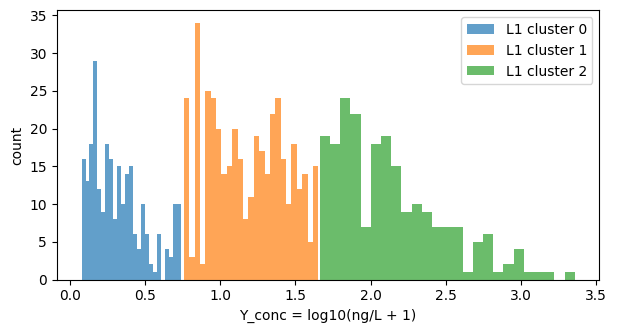

In [4]:
def ordered_kmeans_labels(v, k=K, seed=SEED):
    km = KMeans(n_clusters=k, n_init=20, random_state=seed).fit(v.reshape(-1, 1))
    order = np.argsort(km.cluster_centers_.ravel())          # low -> high
    remap = {old: new for new, old in enumerate(order)}
    return np.array([remap[l] for l in km.labels_]), np.sort(km.cluster_centers_.ravel())

L1, centers = ordered_kmeans_labels(y_cont)
L2 = pd.qcut(y_cont, K, labels=False)
labels = {"L1_kmeans": L1, "L2_tertiles": L2}

print("L1 centres (log10(c+1)):", centers.round(2), "-> ng/L:", (10**centers - 1).round(1))
for n, l in labels.items():
    print(n, dict(zip(*np.unique(l, return_counts=True))))

fig, ax = plt.subplots(figsize=(7, 3.5))
for c in range(K):
    ax.hist(y_cont[L1 == c], bins=25, alpha=.7, label=f"L1 cluster {c}")
ax.set_xlabel("Y_conc = log10(ng/L + 1)"); ax.set_ylabel("count"); ax.legend(); plt.show()

## 4. Classifiers and validation
SVM, Logistic Regression, Random Forest. Imputation and scaling sit **inside** the pipeline so they're fit only on training folds.

- **Paper-style**: stratified 5-fold CV.
- **Grouped**: 5-fold CV where all samples from one location stay in the same fold. Expect lower, more honest scores.

In [5]:
def make_models():
    imp = lambda: SimpleImputer(strategy="median")
    return {
        "SVM": Pipeline([("i", imp()), ("s", StandardScaler()), ("m", SVC(kernel="rbf", C=1.0, random_state=SEED))]),
        "LR":  Pipeline([("i", imp()), ("s", StandardScaler()), ("m", LogisticRegression(max_iter=2000, random_state=SEED))]),
        "RF":  Pipeline([("i", imp()), ("m", RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1))]),
    }

rows = []
for lname, y in labels.items():
    for cvname, cv, kw in [
        ("stratified 5-fold", StratifiedKFold(5, shuffle=True, random_state=SEED), {}),
        ("grouped 5-fold",    StratifiedGroupKFold(5, shuffle=True, random_state=SEED), {"groups": groups}),
    ]:
        for mname, model in make_models().items():
            r = cross_validate(model, X, y, cv=cv, scoring=["accuracy", "f1_macro"], **kw)
            rows.append(dict(labels=lname, cv=cvname, model=mname,
                             acc_mean=r["test_accuracy"].mean(), acc_sd=r["test_accuracy"].std(),
                             f1_macro=r["test_f1_macro"].mean()))
res = pd.DataFrame(rows).round(3)
display(res)
print("Chance level (majority-class share):",
      {n: round(np.bincount(l).max() / len(l), 3) for n, l in labels.items()})

,labels,cv,model,acc_mean,acc_sd,f1_macro
0,L1_kmeans,stratified 5-fold,SVM,0.716,0.021,0.706
1,L1_kmeans,stratified 5-fold,LR,0.669,0.042,0.658
2,L1_kmeans,stratified 5-fold,RF,0.710,0.024,0.698
3,L1_kmeans,grouped 5-fold,SVM,0.695,0.036,0.675
4,L1_kmeans,grouped 5-fold,LR,0.643,0.025,0.618
5,L1_kmeans,grouped 5-fold,RF,0.698,0.046,0.680
6,L2_tertiles,stratified 5-fold,SVM,0.668,0.022,0.663
7,L2_tertiles,stratified 5-fold,LR,0.630,0.038,0.622
8,L2_tertiles,stratified 5-fold,RF,0.688,0.018,0.683
9,L2_tertiles,grouped 5-fold,SVM,0.651,0.035,0.642


Chance level (majority-class share): {'L1_kmeans': np.float64(0.462), 'L2_tertiles': np.float64(0.359)}


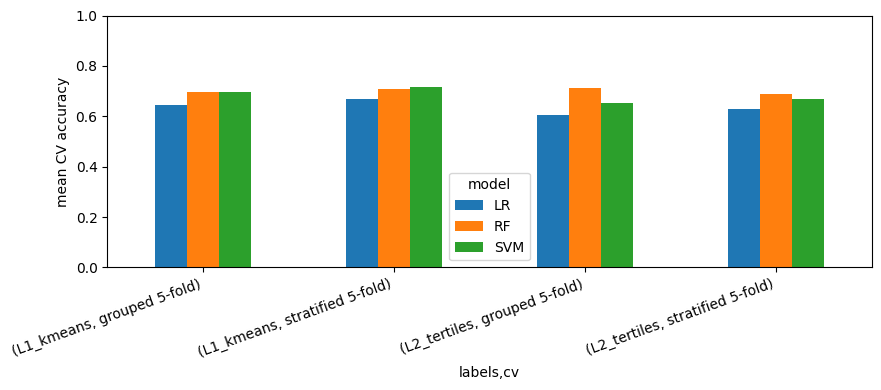

In [6]:
piv = res.pivot_table(index=["labels", "cv"], columns="model", values="acc_mean")
piv.plot.bar(figsize=(9, 4)); plt.ylabel("mean CV accuracy"); plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

## 5. Random Forest feature importance

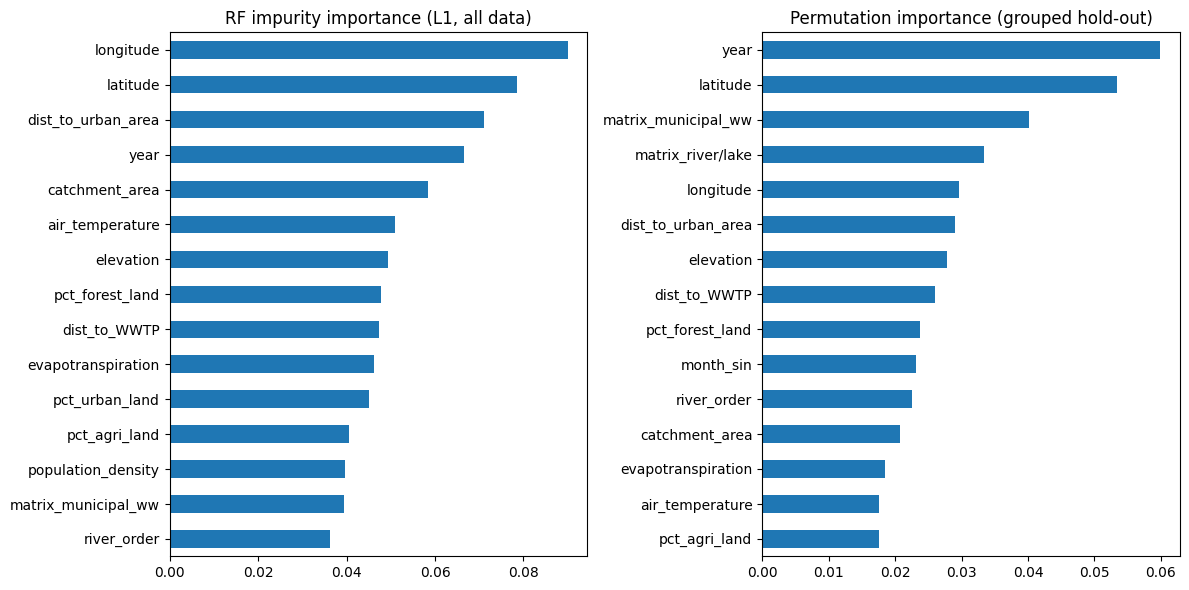

In [7]:
from sklearn.inspection import permutation_importance
y = labels["L1_kmeans"]
rf = make_models()["RF"].fit(X, y)
imp_gini = pd.Series(rf.named_steps["m"].feature_importances_, index=X.columns)

# permutation importance on a grouped hold-out split (less biased than Gini)
tr, te = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X, y, groups))
rf_h = make_models()["RF"].fit(X.iloc[tr], y[tr])
pi = permutation_importance(rf_h, X.iloc[te], y[te], n_repeats=20, random_state=SEED, n_jobs=-1)
imp_perm = pd.Series(pi.importances_mean, index=X.columns)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
imp_gini.sort_values().tail(15).plot.barh(ax=axes[0], title="RF impurity importance (L1, all data)")
imp_perm.sort_values().tail(15).plot.barh(ax=axes[1], title="Permutation importance (grouped hold-out)")
plt.tight_layout(); plt.show()

## 6. Clusters from the predictors alone, and overlap with concentration clusters
Same idea as the paper's K-means on descriptors: cluster the predictor space with K-means (K=3), then measure agreement with the label clusters. Cluster IDs are arbitrary, so they are matched with the Hungarian algorithm. Overlap is the share of samples that land in "matching" clusters — it is **not** a prediction accuracy.

In [8]:
Xs = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X))
Xc = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit_predict(Xs)

def overlap(a, b):
    cm = confusion_matrix(a, b)
    r, c = linear_sum_assignment(-cm)
    return cm[r, c].sum() / cm.sum(), cm

for lname, l in labels.items():
    ov, cm = overlap(l, Xc)
    print(f"{lname}: overlap = {ov:.1%} | ARI = {adjusted_rand_score(l, Xc):.3f}")
    display(pd.DataFrame(cm, index=[f"label {i}" for i in range(K)], columns=[f"X-cluster {i}" for i in range(K)]))

L1_kmeans: overlap = 56.3% | ARI = 0.119


,X-cluster 0,X-cluster 1,X-cluster 2
label 0,11,141,103
label 1,55,271,76
label 2,116,67,31


L2_tertiles: overlap = 48.6% | ARI = 0.082


,X-cluster 0,X-cluster 1,X-cluster 2
label 0,15,191,107
label 1,28,177,63
label 2,139,111,40


## 7. Kruskal–Wallis: do predictors differ across concentration clusters?
Raw p-values at p<0.05 as in the paper, plus Benjamini–Hochberg-adjusted q-values because ~25 features are tested at once. Significance ≠ causation.

In [9]:
def bh(p):
    p = np.asarray(p); n = len(p); o = np.argsort(p)
    q = np.empty(n); q[o] = np.minimum.accumulate((p[o] * n / np.arange(1, n + 1))[::-1])[::-1]
    return np.clip(q, 0, 1)

out = {}
for lname, l in labels.items():
    recs = []
    for col in X.columns:
        groups_c = [X.loc[l == c, col].dropna().values for c in range(K)]
        if min(len(g) for g in groups_c) < 3 or X[col].nunique() < 2:
            continue
        try: H, p = kruskal(*groups_c)
        except ValueError: continue
        recs.append((col, H, p))
    t = pd.DataFrame(recs, columns=["feature", "H", "p"])
    t["q_BH"] = bh(t.p.values)
    t["sig_p<0.05"] = t.p < 0.05; t["sig_q<0.05"] = t.q_BH < 0.05
    out[lname] = t.sort_values("p")
    print(f"\n=== {lname} ==="); display(out[lname].round(4).head(12))


=== L1_kmeans ===


,feature,H,p,q_BH,sig_p<0.05,sig_q<0.05
21,matrix_municipal_ww,200.0562,0.0,0.0,True,True
19,dist_to_urban_area,187.9571,0.0,0.0,True,True
22,matrix_river/lake,170.5408,0.0,0.0,True,True
11,pct_urban_land,118.4039,0.0,0.0,True,True
16,river_order,100.7360,0.0,0.0,True,True
15,catchment_area,90.7585,0.0,0.0,True,True
0,latitude,86.0871,0.0,0.0,True,True
1,longitude,74.8079,0.0,0.0,True,True
2,year,68.3607,0.0,0.0,True,True
14,population_density,57.7139,0.0,0.0,True,True



=== L2_tertiles ===


,feature,H,p,q_BH,sig_p<0.05,sig_q<0.05
21,matrix_municipal_ww,196.0267,0.0,0.0,True,True
22,matrix_river/lake,161.7833,0.0,0.0,True,True
19,dist_to_urban_area,144.9441,0.0,0.0,True,True
0,latitude,109.3016,0.0,0.0,True,True
16,river_order,104.7213,0.0,0.0,True,True
11,pct_urban_land,98.5588,0.0,0.0,True,True
15,catchment_area,89.9891,0.0,0.0,True,True
1,longitude,88.8908,0.0,0.0,True,True
2,year,49.3502,0.0,0.0,True,True
14,population_density,43.3424,0.0,0.0,True,True


## 8. Appendix — the paper's actual pipeline (removal efficiency → C1 / C2 → classifiers)
Run this on a **long-format treatment-train table** with columns:

`facility, compound, process, trip, peak_in, peak_out` (+ a descriptor table with `compound, E, S, A, B, V, L, logKow`).

A synthetic demo runs below so you can check the code works. Swap in your real tables where marked.
Two interpretation choices are mine, not the paper's confirmed implementation: (i) the "Same" tolerance (`TOL`), and (ii) C2 compares each process's mean RE with the preceding process's mean RE. Check against the paper's SI.

In [10]:
def removal_efficiency(df_long):
    d = df_long.copy()
    d["RE"] = (d.peak_in - d.peak_out) / d.peak_in * 100
    d.loc[d.peak_in <= 0, "RE"] = np.nan
    return d

def mean_RE_matrix(d, facility):
    # average over sampling trips -> compound x process table (process order = order of appearance)
    f = d[d.facility == facility]
    order = list(dict.fromkeys(f.process))
    return f.groupby(["compound", "process"]).RE.mean().unstack()[order]

def c1_labels(re_mat):
    # C1: most efficient individual process per compound
    return re_mat.idxmax(axis=1)

def c2_pattern(re_mat, peak_out_mean=None, lod=None, tol=5.0):
    # C2: categorical change in RE vs preceding process: Increase / Decrease / Same / B.D.
    d = re_mat.diff(axis=1)
    pat = pd.DataFrame(index=re_mat.index, columns=re_mat.columns, dtype=object)
    pat.iloc[:, 0] = np.where(re_mat.iloc[:, 0] > tol, "Decrease", np.where(re_mat.iloc[:, 0] < -tol, "Increase", "Same"))
    for j in range(1, re_mat.shape[1]):
        # RE going up = abundance going down
        pat.iloc[:, j] = np.where(d.iloc[:, j] > tol, "Decrease", np.where(d.iloc[:, j] < -tol, "Increase", "Same"))
    pat[re_mat.isna()] = "B.D."
    if peak_out_mean is not None and lod is not None:
        pat[peak_out_mean < lod] = "B.D."
    return pat

def kmodes_c2(pat, k=3, seed=SEED):
    try:
        from kmodes.kmodes import KModes
    except ImportError:
        raise ImportError("pip install kmodes")
    return KModes(n_clusters=k, init="Huang", n_init=10, random_state=seed).fit_predict(pat.values)

# ---------- synthetic demo (replace with: raw = pd.read_csv("your_treatment_data.csv")) ----------
rng = np.random.default_rng(SEED)
comps = [f"cmpd_{i}" for i in range(60)]
procs = ["ActivatedSludge", "BAC", "GAC", "Chlorination"]
recs = []
for c in comps:
    base = rng.uniform(1e4, 1e6); p = base
    eff = rng.uniform(-0.2, 0.9, 4)
    for pr, e in zip(procs, eff):
        for trip in range(4):
            pin = p * rng.uniform(.9, 1.1); recs.append(("PotableReuse", c, pr, trip, pin, pin * (1 - e) * rng.uniform(.9, 1.1)))
        p = p * (1 - e)
raw = pd.DataFrame(recs, columns=["facility", "compound", "process", "trip", "peak_in", "peak_out"])
desc = pd.DataFrame(rng.normal(size=(60, 7)), columns=list("ESABVL") + ["logKow"]); desc.insert(0, "compound", comps)
# ---------------------------------------------------------------------------------------------------

d = removal_efficiency(raw)
re_mat = mean_RE_matrix(d, "PotableReuse").dropna(how="all")      # drop compounds with no data
C1 = c1_labels(re_mat); pat = c2_pattern(re_mat)
print("C1 counts:\n", C1.value_counts())
try:
    C2 = pd.Series(kmodes_c2(pat), index=pat.index); print("\nC2 counts:\n", C2.value_counts())
except ImportError as e:
    C2 = None; print("\nC2 skipped:", e)

Xd = desc.set_index("compound").loc[re_mat.index]
for name, lab in [("C1", C1), ("C2", C2)]:
    if lab is None: continue
    yy = pd.factorize(lab)[0]
    if np.bincount(yy).min() < 5: print(name, "has a class with <5 members; 5-fold CV skipped"); continue
    for mname, m in make_models().items():
        s = cross_validate(m, Xd, yy, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="accuracy")
        print(f"{name} {mname}: {s['test_score'].mean():.3f}")
# (synthetic data has no real signal, so accuracies here only show that the code runs)

C1 counts:
 BAC                16
ActivatedSludge    15
GAC                15
Chlorination       14
Name: count, dtype: int64

C2 skipped: pip install kmodes
C1 SVM: 0.217
C1 LR: 0.250
C1 RF: 0.200
